In [1]:
from em1d.experiment import *
import matplotlib.pyplot as plt
import numpy as np

In [2]:
lp = Loop.square(25)

In [3]:
rx = Receiver()

In [4]:
class Forward2:
    def __init__(self, source, receiver, frequency, tolerance=None):
        self.source = source
        self.receiver = receiver
        self.freq = frequency
        self.rmin = self.source.min_horizontal_distance(self.receiver)
        if self.rmin==0: self.rmin = 1e-2
        self.rmax = self.source.max_horizontal_distance(self.receiver)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.rz = self.receiver.z.flatten()
        self.pfield_dz = torch.abs(self.srcz-self.rz)[0]
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)[0]
        self.device = torch.device('cpu')
        self.tolerance=tolerance        

    @property
    def omega(self):
        return c.twopi*self.freq
    
    def forward(self):
        def wvlngth_integrand(wave_length):
            """ Hz from horizontal electric dipole. """
            lmb = wave_length[None, :]
            tmp_u0 = u0(self.omega, lmb)
            cRTE = rte(self.sigma, self.thick, self.omega, lmb)
            intg = torch.exp(-tmp_u0*self.pfield_dz)+rte(self.sigma, self.thick, self.omega, lmb)*torch.exp(-tmp_u0*self.sfield_dz)
            intg *= lmb**2 / tmp_u0
            return torch.squeeze(intg/c.fourpi)
        
        hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=10)
        r,HR = hkl1.range(self.rmin, self.rmax)
        sofr = s_of_r2(self.source, self.receiver, r)
        return - torch.einsum('...i,...i->...', HR, sofr), sofr, r



    def __call__(self, sigma, thickness):
        if isinstance(sigma, np.ndarray): sigma = torch.from_numpy(sigma)
        if isinstance(thickness, np.ndarray): thickness = torch.from_numpy(thickness)
        self.sigma = (sigma     + 0j).to(self.device)[...,None]
        self.thick = (thickness + 0j).to(self.device)[...,None]
        return self.forward()#.real*c.mu0

In [6]:
class Receiver:
    def __init__(self, x=0., y=0., z=0., grid=True) -> None:
        self.x = tc.tensor(x, dtype=tc.float64)
        self.y = tc.tensor(y, dtype=tc.float64)
        self.z = tc.tensor(z, dtype=tc.float64)
        
        if grid:
            self.grid()
        else:
            npoints = max(len(self.x), len(self.y),len(self.z))
            if len(self.x)==1: self.x = tc.ones(npoints)*self.x
            if len(self.y)==1: self.y = tc.ones(npoints)*self.y
            if len(self.z)==1: self.z = tc.ones(npoints)*self.z

    def grid(self):
        X,Y,Z = tc.meshgrid(self.x, self.y, self.z, indexing='ij')
        self.x = X.squeeze()
        self.y = Y.squeeze()
        self.z = Z.squeeze()
        self.shp = X.shape#+(3,)
        return self
    
    @property
    def xyz(self):
        return tc.squeeze(tc.moveaxis(tc.stack((
                            self.x.flatten(), 
                            self.y.flatten(), 
                            self.z.flatten())), 0, -1))

    def __len__(self):
        return self.x.numel()

In [19]:
def r_edges(r):
    dR_alpha = torch.sqrt(r[1]/r[0])
    R_edge1 = (r/dR_alpha)
    R_edge2 = (r*dR_alpha)
    return R_edge1, R_edge2

def s_of_r2(self, rx, R):
    R = torch.tensor(R, dtype=torch.float64)
    dR_alpha = torch.sqrt(R[1]/R[0])
    R_edge1 = (R/dR_alpha)
    R_edge2 = (R*dR_alpha)
    dR = torch.from_numpy(np.gradient(R.numpy()))

    rx_xyz = rx.xyz
    if len(rx_xyz.shape)==1:
        s = torch.zeros(R.shape, dtype=torch.complex128)
        R_ = R
    else:
        s = torch.zeros(rx_xyz.shape[:-1]+R.shape, dtype=torch.complex128)
        R_edge1 = R_edge1[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_edge2 = R_edge2[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_ = R[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        dR = dR[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    for i in range(len(self)-1):
    # for i in range(1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        x1,y1 = p1[..., 0], p1[..., 1]
        x2,y2 = p2[..., 0], p2[..., 1]
        r_perp = torch.abs(y1)
       
        Rp1 = torch.sqrt(x1**2 + y1**2)
        Rp2 = torch.sqrt(x2**2 + y2**2)
        
        s_norm = torch.abs(p2[..., 0]-p1[..., 0])

        if len(rx_xyz.shape)>1:
            r_perp = r_perp[:, None]*torch.ones_like(R)
            Rp2 = Rp2[:, None]*torch.ones_like(R)
            Rp1 = Rp1[:, None]*torch.ones_like(R)
            s_norm = s_norm[:, None]*torch.ones_like(R)
            x1 = x1[:, None]*torch.ones_like(R)
            x2 = x2[:, None]*torch.ones_like(R)
            y1 = y1[:, None]*torch.ones_like(R)

        ds = torch.zeros_like(R_)
        dx_comp = R_*dR / (R_**2 - r_perp**2)**(1/2)
        dx_comp[R_<=r_perp] = 1.

        maskx = (x1>=0)*(x2>=0)
        maskr = (R_edge2>=Rp1)*(R_edge1<=Rp2)
        ds[maskx*maskr] += dx_comp[maskx*maskr]

        maskx = (x1<0)*(x2>0)
        maskxleft = x1+x2<0
        maskr = (R_edge2>=r_perp)*(R_edge1<=Rp1)

        ds[maskx*maskxleft*maskr] += dx_comp[maskx*maskxleft*maskr]
        
        
        maskxright = x1+x2>=0
        maskr = (R_edge2>=r_perp)*(R_edge1<=Rp2)
        ds[maskx*maskxright*maskr] += dx_comp[maskx*maskxright*maskr]


        maskx = (x1<=0)*(x2<=0)
        maskr = (R_edge2>=Rp2)*(R_edge1<=Rp1)
        ds[maskx*maskr] += dx_comp[maskx*maskr]

        
        ds_sum = torch.nansum(ds, axis=-1, keepdims=True)
        if ds_sum.sum()==0:
            print('ds==0\tr_perp is ', r_perp[0].item())
        ds *= s_norm/ds_sum
        # s += torch.nan_to_num((y1*ds)/R_)
        s += torch.nan_to_num(ds)
    return s#.real

In [20]:
tx = Loop.square(25)
rx = Receiver()
rmin = tx.min_horizontal_distance(rx)
rmax = tx.max_horizontal_distance(rx)
r = np.geomspace(0.1,100, 64)
sofr = s_of_r2(tx, rx, r)

In [21]:
tx = Loop.square(25)
rx1 = Receiver(x=-5, y=-13)
rx2 = Receiver(x=0, y=-13)
rx3 = Receiver(x=0, y=-70)
rmin = tx.min_horizontal_distance(rx)
rmax = tx.max_horizontal_distance(rx)
r = np.geomspace(0.1,100, 64)
sofr1 = s_of_r2(tx, rx1, r)
sofr2 = s_of_r2(tx, rx2, r)
sofr3 = s_of_r2(tx, rx3, r)

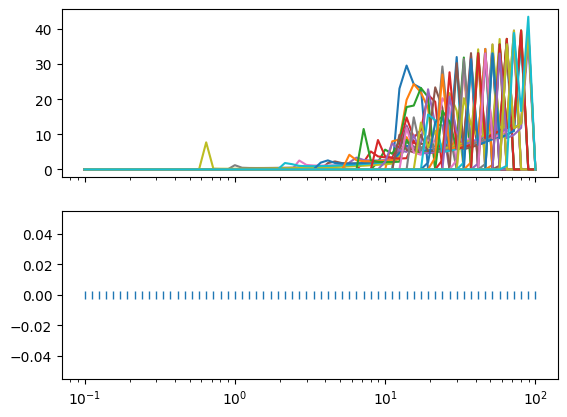

In [22]:
fig,axs = plt.subplots(2,1, sharex=True)
r = np.geomspace(0.1,100, 64)

for yobs in np.linspace(0.1, 80, 50):
    rx = Receiver(y=-yobs)
    
    sofr = s_of_r2(tx, rx, r)
    if sofr.sum()==0: 
        print(yobs)
        axs[1].plot(yobs, 0, 'ro')
    axs[0].semilogx(r, sofr, label=f'y={yobs}')
# axs[0].set_xlim(50, 100)
axs[1].semilogx(r, r*0, '|', label='rx1')


In [23]:
sofr.sum()

tensor(100.+0.j, dtype=torch.complex128)

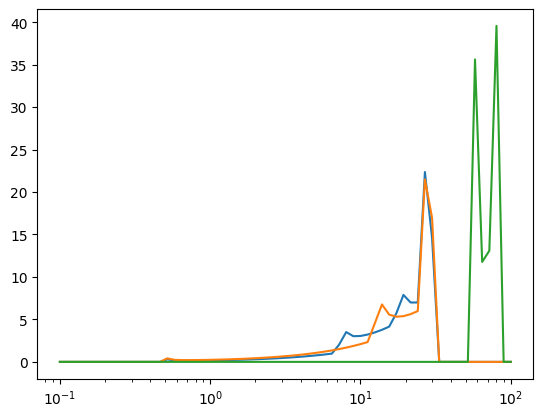

In [24]:
plt.figure()
plt.semilogx(r, sofr1)
plt.semilogx(r, sofr2)
plt.semilogx(r, sofr3)

In [25]:
lp = Loop.square(60)
rxs = Receiver(x=np.linspace(-75, 75, 61), y=np.linspace(-75, 75, 61))
rmin,rmax = lp.min_horizontal_distance(rxs), lp.max_horizontal_distance(rxs)
r = np.geomspace(0.1, rmax, 128)
sofr = s_of_r2(lp, rxs, torch.from_numpy(r))
fwr3 = Forward2(lp, rxs, 2000)

C:\Users\au646858\AppData\Local\Temp\ipykernel_30432\3707840360.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  R = torch.tensor(R, dtype=torch.float64)


In [26]:
n_skip = len(r)//16

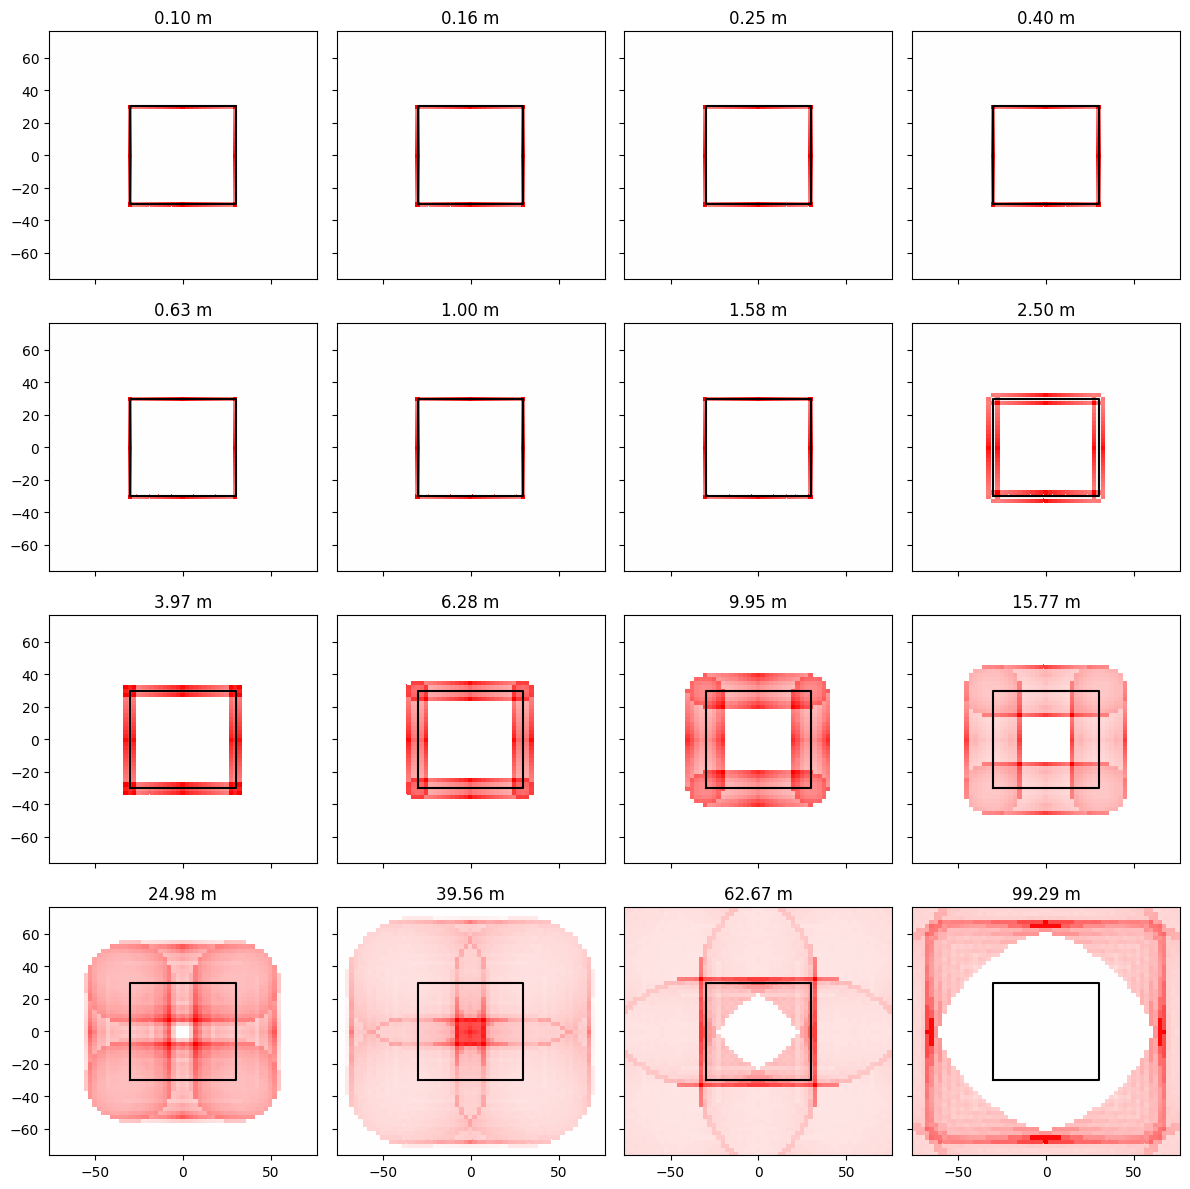

In [27]:
sofrcube = sofr.reshape(rxs.x.shape+r.shape)
fig,axs = plt.subplots(4,4, sharex=True, sharey=True, figsize=(12,12))
for i,ax in enumerate(axs.flatten()):
    ax.set_title(f'{r[i*n_skip]:0.2f} m')
    vlim = max(abs(sofrcube.real[:,:,i*n_skip].min()), abs(sofrcube.real[:,:,i*n_skip].max()))
    pcm=ax.pcolor(rxs.x, rxs.y, sofrcube.real[:,:,i*n_skip], vmin=-vlim, vmax=vlim, cmap='bwr')
    ax.plot(lp.x, lp.y, 'k')
# plt.colorbar(pcm, ax=axs, orientation='horizontal')
plt.tight_layout()
# plt.pcolor(rxs.x, rxs.y, np.abs(sofrcube[:,:,150]))